# Cross-Dataset Diabetes Risk Prediction
## Train on BRFSS (US) → Independent Test on Cambodia STEPS

**Pipeline:**
```
BRFSS 2015+2017+2019 + Cambodia STEPS
  → Feature Alignment (11 shared features)
  → BRFSS 80/20 Train/Validation Split
  → StandardScaler  →  SMOTE (train only)
  → Train 4 Individual Models
  → Validation on BRFSS  →  Select Top 3 by F1  →  Build Ensemble
  → Final Best Model by Validation F1
  → Threshold Tuning (maximise Recall, F1 ≥ floor)
  → Independent Test on Cambodia STEPS
  → SHAP XAI  →  Risk Level  →  Gemini Recommendations
```

**Feature Groups (11 features):**
| Group | Features |
|---|---|
| Demographic | Sex · Age · Education |
| Health Status | HighBP · HighChol · BMI |
| Lifestyle | Smoker · PhysActivity · Fruits · Veggies · HvyAlcoholConsump |

**Evaluation Metrics:**
| Role | Metric |
|---|---|
| Clinical priority | **Recall** (minimise missed diabetics) |
| Model selection | **Validation F1** (primary) |
| Supporting | Accuracy, Precision |

**Saves:** `best_model_cross.pkl` · `scaler_cross.pkl` · `threshold_cross.pkl` · `feature_names_cross.pkl`

## 1. Imports & Configuration

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from dotenv import load_dotenv
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.combine import SMOTETomek

RANDOM_STATE = 42
TARGET_COL   = 'Diabetes_binary'
DATA_DIR     = '../newdata/'

RISK_COLORS = {'Low': '#4CAF50', 'Moderate': '#FF9800', 'High': '#F44336'}

FEATURE_LABELS = {
    'Sex':               'Sex',
    'Age':               'Age group',
    'Education':         'Education level',
    'HighBP':            'High blood pressure',
    'HighChol':          'High cholesterol',
    'BMI':               'BMI',
    'Smoker':            'Smoker',
    'PhysActivity':      'Physical activity',
    'Fruits':            'Fruit consumption',
    'Veggies':           'Vegetable consumption',
    'HvyAlcoholConsump': 'Heavy alcohol use',
    # Engineered
    'BMI_obese':          'Obese (BMI ≥ 30)',
    'HighBP_x_HighChol':  'High BP × High Chol',
    'Inactive_Smoker':    'Inactive smoker',
}

FEATURE_GROUPS = {
    'Demographic':    ['Sex', 'Age', 'Education'],
    'Health Status':  ['HighBP', 'HighChol', 'BMI', 'BMI_obese', 'HighBP_x_HighChol'],
    'Lifestyle':      ['Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'Inactive_Smoker'],
}

print('Libraries loaded.')

Libraries loaded.


In [2]:
from google import genai

load_dotenv('../.env')
GEMINI_API_KEY = os.getenv('GEMINI_API_KEY', '')
gemini_client  = genai.Client(api_key=GEMINI_API_KEY) if GEMINI_API_KEY else None

def get_gemini_recommendations(prob, risk, patient_profile, top_risk_factors, protective_factors):
    payload = {
        'risk_probability': round(float(prob), 2), 'risk_level': risk,
        'patient_profile': patient_profile, 'top_risk_factors': top_risk_factors,
        'protective_factors': protective_factors,
        'instruction': 'Provide simple lifestyle education only. Do not diagnose.',
    }
    prompt = (
        'You are a friendly health educator. Based on this diabetes risk assessment, '
        'provide lifestyle guidance.\n\n' + json.dumps(payload, indent=2)
        + '\n\nRespond ONLY in this JSON (no markdown):\n'
        '{"explanation": "...", "recommendations": ["...","...","...","..."], '
        '"safety_reminder": "..."}'
    )
    try:
        r = gemini_client.models.generate_content(model='gemini-1.5-flash', contents=prompt)
        text = r.text.strip()
        if '```' in text:
            text = text.split('```')[1]
            if text.startswith('json'): text = text[4:]
        return json.loads(text.strip())
    except Exception:
        return {
            'explanation': f'Predicted risk: {prob*100:.0f}% ({risk} level).',
            'recommendations': [
                'Maintain a balanced diet rich in vegetables and whole grains',
                'Engage in at least 150 minutes of moderate exercise per week',
                'Monitor blood pressure and blood glucose regularly',
                'Consult a healthcare professional for personalised advice',
            ],
            'safety_reminder': 'For educational awareness only — not a medical diagnosis.',
        }

print(f'Gemini client ready: {"Yes" if gemini_client else "No API key"}')

Gemini client ready: Yes


## 2. Feature Alignment

BRFSS and STEPS share **11 common features** grouped into three categories.

| Group | Features |
|---|---|
| **Demographic** | Sex, Age, Education |
| **Health Status** | HighBP, HighChol, BMI |
| **Lifestyle** | Smoker, PhysActivity, Fruits, Veggies, HvyAlcoholConsump |

| Alignment Note | Detail |
|---|---|
| **Age encoding** | BRFSS = ordinal group 1–13 · STEPS = actual years → converted via `steps_age_to_brfss_group()` |
| **Excluded (BRFSS-only)** | CholCheck, Stroke, HeartDiseaseorAttack, GenHlth, MentHlth, PhysHlth, DiffWalk, AnyHealthcare, NoDocbcCost, Income |
| **Excluded (STEPS-only)** | Waist\_cm, MeanSystolicBP, MeanDiastolicBP, AlcoholUse, SedentaryMinutes, FruitServingsWeek, VegetableServingsWeek, Income |

In [3]:
# 11 shared features across BRFSS and Cambodia STEPS
TARGET_ALIGNED = [
    'Sex', 'Age', 'Education',                              # Demographic
    'HighBP', 'HighChol', 'BMI',                           # Health Status
    'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump',  # Lifestyle
]

def steps_age_to_brfss_group(age):
    """Map continuous age (years) → BRFSS age group (1–13)."""
    bins   = [0, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74, 79, 999]
    groups = list(range(1, 14))
    for i, (lo, hi) in enumerate(zip(bins, bins[1:])):
        if lo < age <= hi:
            return groups[i]
    return 13

print('Alignment functions defined.')
print(f'Target aligned feature set ({len(TARGET_ALIGNED)}): {TARGET_ALIGNED}')

Alignment functions defined.
Target aligned feature set (11): ['Sex', 'Age', 'Education', 'HighBP', 'HighChol', 'BMI', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump']


## 3. Data Loading

In [4]:
print('Loading BRFSS data...')
dfs = []
for year in [2015, 2017, 2019]:
    df_y = pd.read_csv(DATA_DIR + f'brfss{year}_clean_binary.csv')
    print(f'  {year}: {df_y.shape}  |  diabetes rate: {df_y[TARGET_COL].mean()*100:.1f}%')
    dfs.append(df_y)

df_brfss = pd.concat(dfs, ignore_index=True)
print(f'\nCombined BRFSS: {df_brfss.shape}  |  diabetes rate: {df_brfss[TARGET_COL].mean()*100:.1f}%')

Loading BRFSS data...
  2015: (253680, 22)  |  diabetes rate: 13.9%
  2017: (275746, 22)  |  diabetes rate: 16.0%
  2019: (240493, 22)  |  diabetes rate: 16.9%

Combined BRFSS: (769919, 22)  |  diabetes rate: 15.6%


In [5]:
print('Loading Cambodia STEPS data...')
df_steps = pd.read_csv(DATA_DIR + 'cambodia_diabetes_final_clean.csv')
print(f'  STEPS: {df_steps.shape}  |  diabetes rate: {df_steps[TARGET_COL].mean()*100:.1f}%')
print(f'  STEPS columns: {df_steps.columns.tolist()}')

# Convert Age: actual years → BRFSS age group (1–13)
if 'Age' in df_steps.columns:
    df_steps['Age'] = df_steps['Age'].apply(steps_age_to_brfss_group)
    print('  Age converted: continuous years → BRFSS group (1–13)')

Loading Cambodia STEPS data...
  STEPS: (873, 15)  |  diabetes rate: 14.0%
  STEPS columns: ['Diabetes_binary', 'Sex', 'Age', 'Education', 'BMI', 'Waist_cm', 'HighBP', 'HighChol', 'Smoker', 'AlcoholUse', 'HvyAlcoholConsump', 'PhysActivity', 'SedentaryMinutes', 'Fruits', 'Veggies']
  Age converted: continuous years → BRFSS group (1–13)


Aligned features confirmed (11): ['Sex', 'Age', 'Education', 'HighBP', 'HighChol', 'BMI', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump']


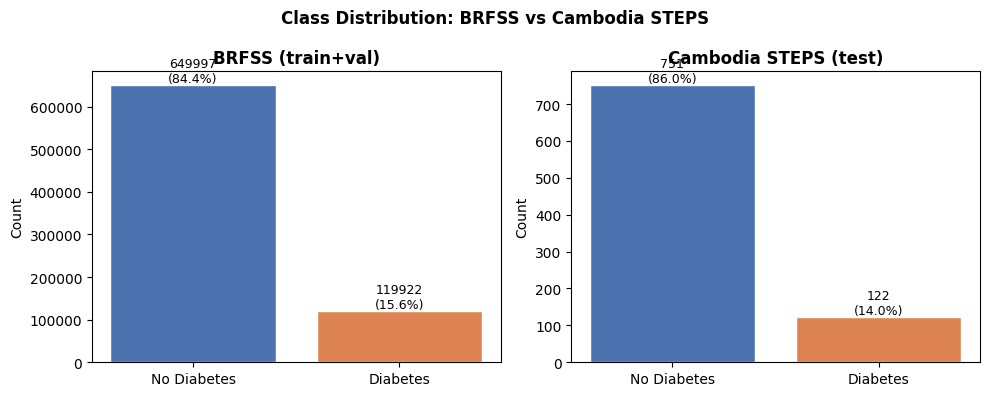

In [6]:
# Confirm which aligned features are present in both datasets
brfss_cols = [c for c in df_brfss.columns if c != TARGET_COL]
steps_cols = [c for c in df_steps.columns if c != TARGET_COL]

ALIGNED_FEATURES = [f for f in TARGET_ALIGNED if f in brfss_cols and f in steps_cols]
missing_brfss = [f for f in TARGET_ALIGNED if f not in brfss_cols]
missing_steps = [f for f in TARGET_ALIGNED if f not in steps_cols]

print(f'Aligned features confirmed ({len(ALIGNED_FEATURES)}): {ALIGNED_FEATURES}')
if missing_brfss: print(f'  Missing from BRFSS: {missing_brfss}')
if missing_steps: print(f'  Missing from STEPS: {missing_steps}')

# Class distribution comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, df_) in zip(axes, [('BRFSS (train+val)', df_brfss), ('Cambodia STEPS (test)', df_steps)]):
    counts = df_[TARGET_COL].value_counts().sort_index()
    ax.bar(['No Diabetes','Diabetes'], counts.values, color=['#4C72B0','#DD8452'], edgecolor='white')
    for i, v in enumerate(counts.values):
        ax.text(i, v + counts.max()*0.01, f'{v}\n({v/len(df_)*100:.1f}%)', ha='center', fontsize=9)
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Count')
plt.suptitle('Class Distribution: BRFSS vs Cambodia STEPS', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

## 4. BRFSS Combine & Split — Stratified 80/20

All three BRFSS years are pooled and split 80/20 (stratified by class):
- **Train (80%)**: model fitting + SMOTE
- **Validation (20%)**: model selection by F1 + threshold tuning
- **Cambodia STEPS**: independent test set — never used during training or selection

                          Rows  Diabetes  No Diabetes  % Positive
Split                                                            
Train — BRFSS 80%       615935     95938       519997        15.6
Validation — BRFSS 20%  153984     23984       130000        15.6
Test — Cambodia STEPS      873       122          751        14.0


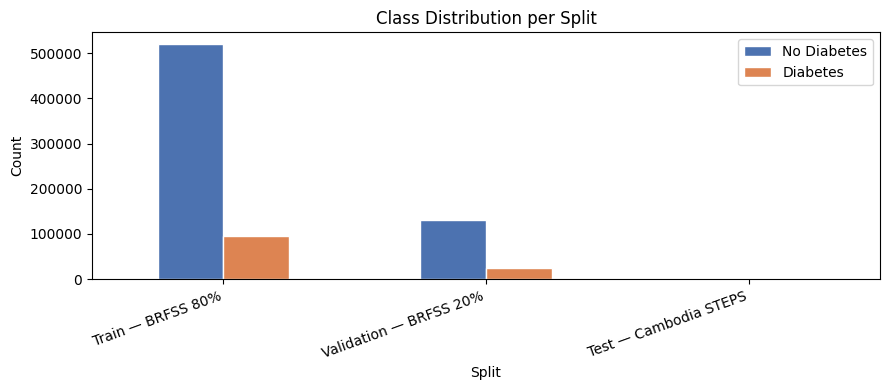

In [7]:
X_brfss = df_brfss[ALIGNED_FEATURES]
y_brfss = df_brfss[TARGET_COL]

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_brfss, y_brfss, test_size=0.20, stratify=y_brfss, random_state=RANDOM_STATE
)

# STEPS independent test
X_test_raw = df_steps[ALIGNED_FEATURES]
y_test     = df_steps[TARGET_COL]

summary = pd.DataFrame([
    {'Split': n, 'Rows': len(s), 'Diabetes': int(s.sum()),
     'No Diabetes': int((s==0).sum()), '% Positive': round(s.mean()*100, 1)}
    for n, s in [('Train — BRFSS 80%', y_train),
                 ('Validation — BRFSS 20%', y_val),
                 ('Test — Cambodia STEPS', y_test)]
]).set_index('Split')
print(summary)

summary[['No Diabetes','Diabetes']].plot(
    kind='bar', figsize=(9, 4), color=['#4C72B0','#DD8452'], edgecolor='white'
)
plt.title('Class Distribution per Split')
plt.ylabel('Count'); plt.xticks(rotation=20, ha='right')
plt.tight_layout(); plt.show()

## 5. Feature Engineering

Three derived features added before scaling — applied identically to train, validation, and STEPS test.

| Feature | Formula | Rationale |
|---|---|---|
| `BMI_obese` | BMI ≥ 30 → 1, else 0 | Non-linear obesity threshold is a strong diabetes signal |
| `HighBP_x_HighChol` | HighBP × HighChol | Co-occurrence of both cardiovascular risk factors |
| `Inactive_Smoker` | (PhysActivity=0) AND (Smoker=1) → 1 | Combined lifestyle risk factor |

In [8]:
# ── Feature Engineering (applied to raw data before scaling) ─────────────────
def add_features(df):
    df = df.copy()
    df['BMI_obese']         = (df['BMI'] >= 30).astype(int)
    df['HighBP_x_HighChol'] = df['HighBP'] * df['HighChol']
    df['Inactive_Smoker']   = ((df['PhysActivity'] == 0) & (df['Smoker'] == 1)).astype(int)
    return df

X_train_raw = add_features(X_train_raw)
X_val_raw   = add_features(X_val_raw)
X_test_raw  = add_features(X_test_raw)

# Update feature list to include engineered columns
ALIGNED_FEATURES = X_train_raw.columns.tolist()
print(f'Feature engineering complete — {len(ALIGNED_FEATURES)} features total:')
print(f'  Original (11) : Sex, Age, Education, HighBP, HighChol, BMI, Smoker, PhysActivity, Fruits, Veggies, HvyAlcoholConsump')
print(f'  Engineered (+3): BMI_obese  |  HighBP_x_HighChol  |  Inactive_Smoker')

Feature engineering complete — 14 features total:
  Original (11) : Sex, Age, Education, HighBP, HighChol, BMI, Smoker, PhysActivity, Fruits, Veggies, HvyAlcoholConsump
  Engineered (+3): BMI_obese  |  HighBP_x_HighChol  |  Inactive_Smoker


## 6. Preprocessing — StandardScaler

Fit on BRFSS train only (after feature engineering). Applied to BRFSS validation and Cambodia STEPS test.

In [9]:
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train_raw)
X_val_s   = scaler.transform(X_val_raw)
X_test_s  = scaler.transform(X_test_raw)
print(f'Scaled — Train: {X_train_s.shape}  Val: {X_val_s.shape}  Test (STEPS): {X_test_s.shape}')

Scaled — Train: (615935, 14)  Val: (153984, 14)  Test (STEPS): (873, 14)


## 7. Class Imbalance Handling — SMOTETomek

**SMOTETomek** = SMOTE (synthetic minority oversampling) + Tomek links (removes borderline ambiguous pairs).  
Produces cleaner class boundaries than pure SMOTE.  
Applied **only to BRFSS training set**. Validation and STEPS test remain untouched real data.

                 Before  After SMOTETomek
Diabetes_binary                          
No Diabetes      519997            515567
Diabetes          95938            515567


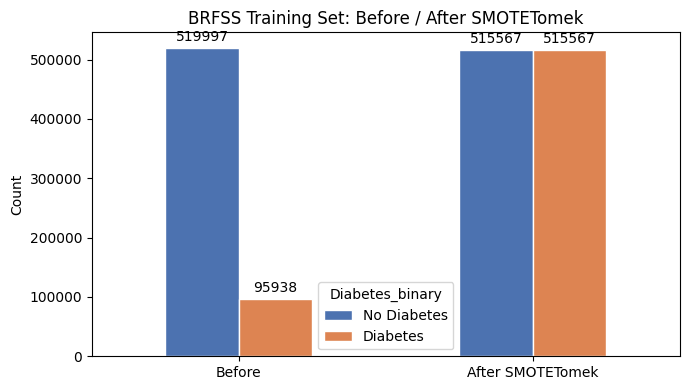

In [10]:
smt = SMOTETomek(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smt.fit_resample(X_train_s, y_train)

before = pd.Series(y_train).value_counts().rename({0:'No Diabetes', 1:'Diabetes'})
after  = pd.Series(y_train_bal).value_counts().rename({0:'No Diabetes', 1:'Diabetes'})
bal_df = pd.DataFrame({'Before': before, 'After SMOTETomek': after})
print(bal_df)

ax = bal_df.T.plot(kind='bar', figsize=(7, 4), color=['#4C72B0','#DD8452'], edgecolor='white')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
plt.title('BRFSS Training Set: Before / After SMOTETomek')
plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 8. Model Training — 5 Individual Models

All trained on SMOTETomek-balanced BRFSS data.  
Stacking ensemble built **after** validation from the best 3 performers.

| # | Model | Strategy |
|---|---|---|
| 1 | Logistic Regression | Fixed hyperparams, balanced class weights |
| 2 | Random Forest | RandomizedSearchCV — 30 iter, 3-fold, F1 |
| 3 | XGBoost | RandomizedSearchCV — 30 iter, 3-fold, F1 |
| 4 | LightGBM | RandomizedSearchCV — 30 iter, 3-fold, F1 |
| 5 | MLP (Neural Network) | RandomizedSearchCV — 10 iter, 3-fold, F1; early stopping |

In [ ]:
individual_models = {}

# 1. Logistic Regression
individual_models['Logistic Regression'] = LogisticRegression(
    max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE
)
individual_models['Logistic Regression'].fit(X_train_bal, y_train_bal)
print('Trained: Logistic Regression')

neg = int((y_train_bal == 0).sum())
pos = int((y_train_bal == 1).sum())
scale_pos = neg / pos if pos > 0 else 1.0

search_spaces = {
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': [100,200,300,500], 'max_depth': [None,8,12,16],
         'min_samples_split': [2,5,10], 'min_samples_leaf': [1,2,4]}
    ),
    'XGBoost': (
        XGBClassifier(scale_pos_weight=scale_pos, eval_metric='logloss',
                      random_state=RANDOM_STATE, n_jobs=-1, tree_method='hist'),
        {'n_estimators': [100,200,300,500], 'max_depth': [3,5,7,9],
         'learning_rate': [0.03,0.05,0.1,0.2], 'subsample': [0.7,0.8,1.0],
         'colsample_bytree': [0.7,0.8,1.0]}
    ),
    'LightGBM': (
        LGBMClassifier(is_unbalance=True, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        {'n_estimators': [100,200,300,500], 'max_depth': [-1,5,10,15],
         'learning_rate': [0.03,0.05,0.1,0.2], 'num_leaves': [31,63,127,255]}
    ),
}

for name, (estimator, param_dist) in search_spaces.items():
    search = RandomizedSearchCV(
        estimator, param_dist, n_iter=30, cv=3,
        scoring='f1', random_state=RANDOM_STATE, n_jobs=-1
    )
    search.fit(X_train_bal, y_train_bal)
    individual_models[name] = search.best_estimator_
    print(f'Tuned {name}  |  best CV F1: {search.best_score_:.4f}')
    print(f'  params: {search.best_params_}')

# 5. MLP — Neural Network
mlp_search = RandomizedSearchCV(
    MLPClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                  random_state=RANDOM_STATE),
    {'hidden_layer_sizes': [(64,32), (128,64), (64,64,32), (128,64,32), (100,50,25)],
     'alpha':              [0.0001, 0.001, 0.01],
     'learning_rate_init': [0.001, 0.005, 0.01]},
    n_iter=10, cv=3, scoring='f1', random_state=RANDOM_STATE, n_jobs=-1
)
mlp_search.fit(X_train_bal, y_train_bal)
individual_models['MLP'] = mlp_search.best_estimator_
print(f'Tuned MLP  |  best CV F1: {mlp_search.best_score_:.4f}')
print(f'  params: {mlp_search.best_params_}')

print(f'\nAll 5 individual models trained.')

## 9. Validation on BRFSS & Model Selection

**Step 1** — Evaluate all 5 individual models on BRFSS validation set.  
**Step 2** — Select top 3 by **Validation F1** (primary) — Recall shown as clinical priority.  
**Step 3** — Build **Stacking Ensemble** (meta-learner: Logistic Regression) from those top 3.  
**Step 4** — Final 4 candidates: top-3 individual + stacking ensemble → select best by **Validation F1**.

In [ ]:
def evaluate(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred  = (proba >= threshold).astype(int)
    return {
        'Recall':    round(recall_score(y, pred, zero_division=0), 4),
        'F1':        round(f1_score(y, pred, zero_division=0), 4),
        'Accuracy':  round(accuracy_score(y, pred), 4),
        'Precision': round(precision_score(y, pred, zero_division=0), 4),
        'ROC-AUC':   round(roc_auc_score(y, proba), 4),
    }

# ── Step 1: Evaluate 5 individual models ─────────────────────────────────────
indiv_results = {n: evaluate(m, X_val_s, y_val) for n, m in individual_models.items()}
indiv_df = pd.DataFrame(indiv_results).T.sort_values('F1', ascending=False)
print('Individual Model Validation Results (sorted by F1):')
print(indiv_df.to_string())

# ── Step 2: Top 3 by F1 ───────────────────────────────────────────────────────
top3_names = indiv_df.nlargest(3, 'F1').index.tolist()
print(f'\nTop 3 selected for stacking → {top3_names}')

# ── Step 3: Build Stacking Ensemble ──────────────────────────────────────────
stacking = StackingClassifier(
    estimators=[(n.lower().replace(' ','_').replace('/','_'), individual_models[n])
                for n in top3_names],
    final_estimator=LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    cv=3, stack_method='predict_proba', n_jobs=1
)
stacking.fit(X_train_bal, y_train_bal)
ensemble_label = f'Stacking ({" + ".join(n.split()[0] for n in top3_names)})'
print(f'Stacking ensemble built: {ensemble_label}')

# ── Step 4: Final 4 candidates ────────────────────────────────────────────────
final_models = {n: individual_models[n] for n in top3_names}
final_models[ensemble_label] = stacking

final_results = {n: evaluate(m, X_val_s, y_val) for n, m in final_models.items()}
val_df = pd.DataFrame(final_results).T.sort_values('F1', ascending=False)
print('\nFinal Candidates — Validation Results (sorted by F1):')
print(val_df.to_string())
print('\nClinical priority: Recall  |  Selection metric: F1  |  Supporting: Accuracy, Precision')

# ── Visualise ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

val_df[['Recall','F1','Accuracy','Precision']].plot(
    kind='bar', ax=axes[0],
    color=['#DD8452','#1976D2','#55A868','#9C27B0'], edgecolor='white'
)
axes[0].set_title('Final Candidate Comparison — Validation Set', fontweight='bold')
axes[0].set_ylabel('Score'); axes[0].set_ylim(0, 1.05)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].legend(loc='lower right')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.3f', fontsize=6.5, padding=2)

val_df['F1'].sort_values().plot(kind='barh', ax=axes[1], color='#1976D2', edgecolor='white')
axes[1].set_title('F1-Score Ranking — Primary Selection Metric', fontweight='bold')
axes[1].set_xlabel('Validation F1-Score')
axes[1].axvline(val_df['F1'].max(), color='red', linestyle='--', lw=1.5, label='Best F1')
axes[1].legend()
for i, (idx, v) in enumerate(val_df['F1'].sort_values().items()):
    axes[1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)

plt.tight_layout(); plt.show()

## 9. Threshold Tuning

**Clinical priority: Recall.**  
Sweep thresholds on the BRFSS validation set. Select the threshold that **maximises Recall** subject to F1 ≥ 0.35.  
In healthcare, missing a true diabetic (false negative) is more costly than a false alarm.

In [ ]:
# Select best model by validation F1
best_name  = val_df['F1'].idxmax()
best_model = final_models[best_name]
print(f'Best model selected: {best_name}')
print(f'  Val F1       : {val_df.loc[best_name,"F1"]:.4f}')
print(f'  Val Recall   : {val_df.loc[best_name,"Recall"]:.4f}')
print(f'  Val Accuracy : {val_df.loc[best_name,"Accuracy"]:.4f}')
print(f'  Val Precision: {val_df.loc[best_name,"Precision"]:.4f}')

F1_FLOOR  = 0.35
proba_val = best_model.predict_proba(X_val_s)[:, 1]
thr_rows  = []
for t in np.arange(0.05, 0.95, 0.01):
    pred = (proba_val >= t).astype(int)
    thr_rows.append({
        'Threshold': round(t, 2),
        'Recall':    recall_score(y_val, pred, zero_division=0),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'F1':        f1_score(y_val, pred, zero_division=0),
    })
thr_df     = pd.DataFrame(thr_rows)
acceptable = thr_df[thr_df['F1'] >= F1_FLOOR]

if len(acceptable) == 0:
    chosen_threshold = 0.5
    print(f'No threshold meets F1 >= {F1_FLOOR}. Using default 0.5.')
else:
    best_thr = acceptable.loc[acceptable['Recall'].idxmax()]
    chosen_threshold = best_thr['Threshold']
    print(f'\nChosen threshold : {chosen_threshold:.2f}')
    print(f'  Recall         : {best_thr["Recall"]:.4f}  ← maximised')
    print(f'  F1             : {best_thr["F1"]:.4f}  (≥ floor {F1_FLOOR})')
    print(f'  Precision      : {best_thr["Precision"]:.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thr_df['Threshold'], thr_df['Recall'],    label='Recall (clinical priority)', color='#DD8452', lw=2)
ax.plot(thr_df['Threshold'], thr_df['F1'],        label='F1',        color='#1976D2', lw=2)
ax.plot(thr_df['Threshold'], thr_df['Precision'], label='Precision', color='#9C27B0', lw=1.5, linestyle='--')
ax.axvline(chosen_threshold, color='red', linestyle='--', lw=1.5, label=f'Chosen ({chosen_threshold:.2f})')
ax.axhline(F1_FLOOR, color='gray', linestyle=':', label=f'F1 floor ({F1_FLOOR})')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title('Threshold Sweep on BRFSS Validation Set')
ax.legend(); plt.tight_layout(); plt.show()

## 10. Final Independent Test — Cambodia STEPS

The best model + chosen threshold are applied to Cambodia STEPS **for the first time**.  
This set was never used in training, validation, or model selection — it is a true independent evaluation.

In [ ]:
proba_test = best_model.predict_proba(X_test_s)[:, 1]
y_pred     = (proba_test >= chosen_threshold).astype(int)

test_metrics = {
    'Recall':    recall_score(y_test, y_pred, zero_division=0),
    'F1':        f1_score(y_test, y_pred, zero_division=0),
    'Accuracy':  accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_test, proba_test),
}
print('=' * 56)
print('  INDEPENDENT TEST — Cambodia STEPS')
print('=' * 56)
print(f'  Model     : {best_name}')
print(f'  Threshold : {chosen_threshold:.2f}')
print(f'  Features  : {len(ALIGNED_FEATURES)} ({ALIGNED_FEATURES})')
print()
for k, v in test_metrics.items():
    marker = ' ← clinical priority' if k == 'Recall' else (' ← selection metric' if k == 'F1' else '')
    print(f'  {k:<12s} {v:.4f}{marker}')
print()
print(classification_report(y_test, y_pred, target_names=['No Diabetes','Diabetes']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Diabetes','Diabetes']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — Cambodia STEPS\n{best_name} (thr={chosen_threshold:.2f})')

for name, m in final_models.items():
    p = m.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)
    lw  = 2.5 if name == best_name else 1.0
    axes[1].plot(fpr, tpr, lw=lw, label=f'{name} (AUC={auc:.3f})')
axes[1].plot([0,1],[0,1],'k--', alpha=0.4)
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves — Cambodia STEPS Test (final candidates)')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

comparison = pd.DataFrame({
    'Validation (BRFSS)': val_df.loc[best_name, ['Recall','F1','Accuracy','Precision']],
    'Test (STEPS)':        pd.Series({k: test_metrics[k] for k in ['Recall','F1','Accuracy','Precision']}),
})
print('\nVal vs Test Comparison:')
print(comparison.round(4).to_string())

## 11. XAI — SHAP Explainability

SHAP computed on Cambodia STEPS test set to explain feature contributions for the Cambodian population.

In [ ]:
TREE_MODELS = ['LightGBM','XGBoost','Random Forest']

if best_name in TREE_MODELS:
    shap_model = best_model
    shap_model_name = best_name
else:
    tree_candidates = [n for n in TREE_MODELS if n in individual_models]
    shap_model_name = indiv_df.loc[indiv_df.index.isin(tree_candidates), 'F1'].idxmax()
    shap_model = individual_models[shap_model_name]
    shap_model_name += ' (SHAP proxy — best tree)'

print(f'SHAP computed on: {shap_model_name}')

explainer   = shap.TreeExplainer(shap_model)
shap_values = explainer(X_test_s)

if shap_values.values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

print(f'SHAP values shape: {sv.values.shape}')

mean_shap     = pd.Series(np.abs(sv.values).mean(axis=0), index=ALIGNED_FEATURES).sort_values(ascending=True)
labels_mapped = [FEATURE_LABELS.get(f, f) for f in mean_shap.index]
palette       = ['#DD8452' if v > mean_shap.median() else '#4C72B0' for v in mean_shap]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(labels_mapped, mean_shap.values, color=palette)
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('Global Feature Importance — Cambodia STEPS Test Set', fontweight='bold')
plt.tight_layout(); plt.show()

shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title('SHAP Beeswarm — Cambodia STEPS Patients')
plt.tight_layout(); plt.show()

## 12. Risk Level Output

| Risk Level | Probability |
|---|---|
| Low | < 30 % |
| Moderate | 30 % – 70 % |
| High | ≥ 70 % |

In [ ]:
def risk_label(prob):
    return 'High' if prob >= 0.70 else ('Moderate' if prob >= 0.30 else 'Low')

test_report = X_test_raw.copy().reset_index(drop=True)
test_report['True Label']  = y_test.values
test_report['Probability'] = proba_test.round(3)
test_report['Risk Level']  = test_report['Probability'].apply(risk_label)
test_report['Prediction']  = y_pred

risk_dist = test_report['Risk Level'].value_counts().reindex(['Low','Moderate','High'])
print('Risk distribution — Cambodia STEPS:')
print(risk_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for lab, grp in test_report.groupby('True Label'):
    axes[0].hist(grp['Probability'], bins=20, alpha=0.65,
                 label=['No Diabetes','Diabetes'][int(lab)], density=True)
axes[0].axvline(0.30, color='orange', linestyle='--', label='30% cutoff')
axes[0].axvline(0.70, color='red',    linestyle='--', label='70% cutoff')
axes[0].set_xlabel('Predicted Probability')
axes[0].set_title('Probability Distribution by True Class')
axes[0].legend()

risk_dist.plot(kind='bar', ax=axes[1],
               color=[RISK_COLORS[r] for r in risk_dist.index], edgecolor='white')
for p in axes[1].patches:
    axes[1].annotate(str(int(p.get_height())),
                     (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
axes[1].set_title('Risk Tier Distribution — Cambodia STEPS')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(risk_dist.index, rotation=0)
plt.tight_layout(); plt.show()

## 13. Actionable Recommendations — Patient Dashboard

In [ ]:
def patient_dashboard(patient_idx, use_gemini=True):
    prob       = float(proba_test[patient_idx])
    risk       = risk_label(prob)
    true_label = int(y_test.values[patient_idx])
    shap_vals  = sv.values[patient_idx]
    row        = X_test_raw.iloc[patient_idx]

    order     = np.argsort(np.abs(shap_vals))[::-1]
    top_feats = [ALIGNED_FEATURES[i] for i in order[:4]]
    top_vals  = [shap_vals[i] for i in order[:4]]

    gc = {}
    for grp, feats in FEATURE_GROUPS.items():
        idxs = [ALIGNED_FEATURES.index(f) for f in feats if f in ALIGNED_FEATURES]
        gc[grp] = float(np.abs(shap_vals[idxs]).sum())
    gc_total = sum(gc.values()) or 1
    gc_pct   = {k: v/gc_total*100 for k, v in gc.items()}

    risk_feats = [FEATURE_LABELS.get(ALIGNED_FEATURES[i], ALIGNED_FEATURES[i])
                  for i in np.argsort(shap_vals)[::-1][:4] if shap_vals[i] > 0]
    prot_feats = [FEATURE_LABELS.get(ALIGNED_FEATURES[i], ALIGNED_FEATURES[i])
                  for i in np.argsort(shap_vals)[:4] if shap_vals[i] < 0]
    patient_profile = {
        'Age_group': int(row.get('Age', 0)),
        'BMI':       round(float(row.get('BMI', 0)), 1),
        'HighBP':    int(row.get('HighBP', 0)),
        'PhysActive':int(row.get('PhysActivity', 0)),
        'Smoker':    int(row.get('Smoker', 0)),
    }

    if use_gemini and gemini_client:
        gem = get_gemini_recommendations(prob, risk, patient_profile, risk_feats, prot_feats)
    else:
        gem = {
            'explanation': f'Predicted diabetes risk: {prob*100:.0f}% ({risk} level).',
            'recommendations': [
                'Maintain a balanced diet with more vegetables and whole grains',
                'Exercise at least 150 minutes per week',
                'Monitor blood pressure and blood sugar regularly',
                'Consult a healthcare professional for personalised advice',
            ],
            'safety_reminder': 'For educational awareness only — not a medical diagnosis.',
        }
    recs = gem.get('recommendations', [])[:4]

    risk_color   = RISK_COLORS[risk]
    group_colors = ['#1976D2', '#FF9800', '#4CAF50']  # Demographic, Health Status, Lifestyle
    rec_colors   = ['#1976D2','#43A047','#E53935','#FB8C00']

    fig = plt.figure(figsize=(18, 7))
    fig.patch.set_facecolor('#FAFAFA')
    gs  = fig.add_gridspec(1, 4, wspace=0.38)

    ax1 = fig.add_subplot(gs[0]); ax1.set_facecolor('white'); ax1.axis('off')
    ax1.text(0.5, 0.93, 'Patient Result', ha='center', fontsize=13, fontweight='bold', transform=ax1.transAxes)
    ax1.text(0.5, 0.66, f'{prob*100:.0f}%', ha='center', fontsize=46, fontweight='bold', color='#1A1A2E', transform=ax1.transAxes)
    ax1.text(0.5, 0.48, f'{risk} Risk', ha='center', fontsize=18, fontweight='bold', color=risk_color, transform=ax1.transAxes)
    for x0, x1c, c in [(0.05,0.32,'#4CAF50'),(0.32,0.58,'#FF9800'),(0.58,0.95,'#F44336')]:
        ax1.barh(0.30, x1c-x0, left=x0, height=0.06, color=c, transform=ax1.transAxes)
    needle = min(0.05 + prob*0.90, 0.93)
    ax1.annotate('', xy=(needle, 0.37), xytext=(needle, 0.45),
                 xycoords='axes fraction', textcoords='axes fraction',
                 arrowprops=dict(arrowstyle='->', color='black', lw=2))
    ax1.text(0.5, 0.14, 'Predicted diabetes risk probability', ha='center', fontsize=8, color='gray', transform=ax1.transAxes)
    ax1.set_xlim(0,1); ax1.set_ylim(0,1)
    for sp in ax1.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax2 = fig.add_subplot(gs[1]); ax2.set_facecolor('white')
    bar_colors = ['#F44336' if v > 0 else '#4CAF50' for v in top_vals]
    y_pos = list(range(len(top_feats)-1, -1, -1))
    ax2.barh(y_pos, top_vals, color=bar_colors, height=0.55)
    labels = [f'{FEATURE_LABELS.get(f,f)}\n{"increases" if v>0 else "reduces"} risk'
              for f, v in zip(top_feats, top_vals)]
    ax2.set_yticks(y_pos); ax2.set_yticklabels(labels, fontsize=8.5)
    ax2.axvline(0, color='black', linewidth=0.8)
    ax2.set_title('Main Reasons', fontsize=13, fontweight='bold', pad=10)
    ax2.set_xlabel('SHAP value')
    for i, y in enumerate(y_pos):
        cc = '#F44336' if top_vals[i] > 0 else '#4CAF50'
        ax2.annotate(str(i+1), xy=(ax2.get_xlim()[0], y), fontsize=9, color='white', fontweight='bold',
                     bbox=dict(boxstyle='circle,pad=0.25', fc=cc, ec='none'))
    for sp in ax2.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax3 = fig.add_subplot(gs[2]); ax3.set_facecolor('white')
    grp_names = list(gc_pct.keys()); grp_vals = [gc_pct[g] for g in grp_names]
    wedges, _ = ax3.pie(grp_vals, colors=group_colors, startangle=90, counterclock=False,
                        wedgeprops={'width':0.5,'edgecolor':'white','linewidth':2})
    ax3.legend(wedges, [f'{g}: {v:.0f}%' for g,v in zip(grp_names,grp_vals)],
               loc='lower center', bbox_to_anchor=(0.5,-0.22), fontsize=8, frameon=False)
    ax3.set_title('Group Insight', fontsize=13, fontweight='bold')
    top_grp = max(gc_pct, key=gc_pct.get)
    ax3.text(0.5, -0.34, f'{top_grp} is the main\ncategory driving\nthis risk',
             ha='center', fontsize=8.5, color='#444444', transform=ax3.transAxes)
    for sp in ax3.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax4 = fig.add_subplot(gs[3]); ax4.set_facecolor('white'); ax4.axis('off')
    ax4.text(0.5, 0.97, 'Actionable\nRecommendation',
             ha='center', va='top', fontsize=12, fontweight='bold', transform=ax4.transAxes)
    explanation = gem.get('explanation','')
    for li, line in enumerate(textwrap.wrap(explanation, 42)[:3]):
        ax4.text(0.05, 0.86-li*0.055, line, ha='left', fontsize=7.5,
                 color='#333333', style='italic', transform=ax4.transAxes)
    for i, rec in enumerate(recs):
        yr = 0.66 - i*0.155
        ax4.text(0.09, yr, str(i+1), ha='center', va='center',
                 fontsize=10, color='white', fontweight='bold', transform=ax4.transAxes,
                 bbox=dict(boxstyle='circle,pad=0.3', fc=rec_colors[i], ec='none'))
        for wi, wl in enumerate(textwrap.wrap(rec, 35)[:2]):
            ax4.text(0.18, yr-wi*0.045, wl, ha='left', va='center',
                     fontsize=8, color='#1A1A2E', transform=ax4.transAxes)
        ax4.plot([0,1],[yr-0.065,yr-0.065],'#EEEEEE', lw=1, transform=ax4.transAxes)
    ax4.text(0.5, 0.03, gem.get('safety_reminder','')[:70],
             ha='center', fontsize=7, color='#999999', style='italic', transform=ax4.transAxes)
    for sp in ax4.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    fig.suptitle(
        f'Patient #{patient_idx}  |  True: {["No Diabetes","Diabetes"][true_label]}  |  '
        f'Train: BRFSS  →  Test: Cambodia STEPS',
        fontsize=10, color='#555555', y=1.01
    )
    plt.show()
    return prob, risk

high_idx = int(np.argmax(proba_test))
print(f'High-risk patient: #{high_idx}')
patient_dashboard(high_idx)

mod_mask = (proba_test >= 0.30) & (proba_test < 0.60)
if mod_mask.any():
    patient_dashboard(int(np.where(mod_mask)[0][0]))

In [ ]:
print('=' * 56)
print('  FINAL SUMMARY — Cross-Dataset Evaluation')
print('=' * 56)
print(f'  Train / Val  : BRFSS 2015+2017+2019  (80/20 stratified)')
print(f'  Test         : Cambodia STEPS (873 records)')
print(f'  Features     : {len(ALIGNED_FEATURES)} aligned  {ALIGNED_FEATURES}')
print(f'  Best model   : {best_name}')
print(f'  Threshold    : {chosen_threshold:.2f}')
print()
print(f'  {"Metric":<12s} {"Validation (BRFSS)":>20s} {"Test (STEPS)":>14s}')
print('  ' + '-'*50)
for k in ['Recall','F1','Accuracy','Precision']:
    val_v  = val_df.loc[best_name, k]
    test_v = test_metrics[k]
    note   = '← clinical' if k=='Recall' else ('← selection' if k=='F1' else '')
    print(f'  {k:<12s} {val_v:>20.4f} {test_v:>14.4f}  {note}')
print()
print('  Risk tier breakdown (STEPS test):')
print(test_report['Risk Level'].value_counts().reindex(['High','Moderate','Low']))

## 14. Save Model & Artefacts

In [ ]:
joblib.dump(best_model,       'best_model_cross.pkl')
joblib.dump(scaler,           'scaler_cross.pkl')
joblib.dump(chosen_threshold, 'threshold_cross.pkl')
joblib.dump(ALIGNED_FEATURES, 'feature_names_cross.pkl')
print(f'Saved: best_model_cross.pkl    ({best_name})')
print(f'Saved: scaler_cross.pkl')
print(f'Saved: threshold_cross.pkl     ({chosen_threshold:.2f})')
print(f'Saved: feature_names_cross.pkl ({len(ALIGNED_FEATURES)} features)')